# **Rainfall Prediction Using Machine Learning**

# **Name- Anamika Bej**
# **Reg No.- B2530102**

# **Importing Dependencies**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import (
    GridSearchCV,
    TimeSeriesSplit,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

sns.set(style="whitegrid")

# **Data Collection**

In [ ]:
csv_path = "/content/kolkata_weather_jan_june_2026.csv"
if os.path.exists(csv_path):
    data = pd.read_csv(csv_path)
    print("Dataset loaded from CSV file.")
elif 'data' in globals() or 'data' in locals():
    print("CSV file not found, but 'data' DataFrame is already loaded in memory. Using existing 'data'.")
else:
    raise FileNotFoundError(f"Could not find '{csv_path}' and no existing 'data' DataFrame was found in memory. Please upload the file.")

# Clean column names
data.columns = data.columns.str.strip()

# Convert date column
data['time'] = pd.to_datetime(data['time'])

# Sort data chronologically
data = data.sort_values('time').reset_index(drop=True)

# Check duplicate dates
print("Duplicate dates:", data['time'].duplicated().sum())

# Remove duplicate dates, if any
data = data.drop_duplicates(subset='time').reset_index(drop=True)

# Check chronological continuity
date_gaps = data['time'].diff().dt.days
gap_count = (date_gaps.dropna() != 1).sum()

print("Missing or irregular date intervals:", gap_count)

# Stop if dates are not consecutive
if gap_count > 0:
    raise ValueError(
        "Missing or irregular dates detected. "
        "Please check the dataset before creating "
        "the next-day rainfall target."
    )
raw_data = data.copy()
# Create next-day rainfall target
data['rainfall'] = (
    data['rain_sum'].shift(-1) > 0
).astype(int)

# Remove last row because next-day rainfall is unknown
data = data.iloc[:-1].copy()

# Verify next-day rainfall target
# Adjusted to 1826 to match actual dataset size
assert len(data) == 1826
assert data['rainfall'].notna().all()

print("Target verification successful!")
print("Total records:", len(data))
print("\nNext-day rainfall distribution:")
print(data['rainfall'].value_counts())


# Display dataset information
print("\nDataset shape:", data.shape)

print("\nDate range:")
print("Start:", data['time'].min())
print("End:", data['time'].max())

print("\nRainfall distribution:")
print(data['rainfall'].value_counts())

print("\nMissing values:")
print(data.isnull().sum())

Dataset loaded from CSV file.
Duplicate dates: 0
Missing or irregular date intervals: 0
Target verification successful!
Total records: 1826

Next-day rainfall distribution:
rainfall
1    1020
0     806
Name: count, dtype: int64

Dataset shape: (1826, 18)

Date range:
Start: 2021-06-30 00:00:00
End: 2026-06-29 00:00:00

Rainfall distribution:
rainfall
1    1020
0     806
Name: count, dtype: int64

Missing values:
time                           0
weather_code                   0
temperature_2m_mean            0
temperature_2m_max             0
temperature_2m_min             0
precipitation_sum              0
rain_sum                       0
precipitation_hours            0
wind_speed_10m_max             0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
sunrise                        0
sunset                         0
sunshine_duration              0
city                           0
latitude                       0
longitude                      0
rainfall               

In [ ]:
data.head()

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude,rainfall
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639,1
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639,1
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639,1
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639,1
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639,1


In [ ]:
data.tail()

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude,rainfall
1821,2026-06-25,55,29.7,34.9,27.1,3.1,3.1,7.0,13.8,33.8,164,2026-06-25T04:53,2026-06-25T18:24,37225.06,Kolkata,22.5726,88.3639,1
1822,2026-06-26,63,29.8,32.9,27.0,6.2,6.2,5.0,9.3,27.4,166,2026-06-26T04:54,2026-06-26T18:25,44119.09,Kolkata,22.5726,88.3639,1
1823,2026-06-27,53,30.2,34.3,27.5,2.0,2.0,8.0,12.3,26.6,160,2026-06-27T04:54,2026-06-27T18:25,43842.12,Kolkata,22.5726,88.3639,1
1824,2026-06-28,63,29.7,32.8,27.5,12.6,12.6,11.0,12.0,33.1,182,2026-06-28T04:54,2026-06-28T18:25,40811.67,Kolkata,22.5726,88.3639,1
1825,2026-06-29,63,29.2,34.0,27.1,24.5,24.5,13.0,10.5,25.9,177,2026-06-29T04:54,2026-06-29T18:25,24217.54,Kolkata,22.5726,88.3639,1


# **Data Preprocessing**

In [ ]:
data.info()

print("\nDataset shape:", data.shape)

print("\nAvailable columns:")
print(data.columns.tolist())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   time                         1826 non-null   datetime64[ns]
 1   weather_code                 1826 non-null   int64         
 2   temperature_2m_mean          1826 non-null   float64       
 3   temperature_2m_max           1826 non-null   float64       
 4   temperature_2m_min           1826 non-null   float64       
 5   precipitation_sum            1826 non-null   float64       
 6   rain_sum                     1826 non-null   float64       
 7   precipitation_hours          1826 non-null   float64       
 8   wind_speed_10m_max           1826 non-null   float64       
 9   wind_gusts_10m_max           1826 non-null   float64       
 10  wind_direction_10m_dominant  1826 non-null   int64         
 11  sunrise                      1826 non-null 

In [ ]:
# Checking class distribution

print("Rainfall Class Distribution:")
print(data['rainfall'].value_counts())

print("\nClass Distribution in Percentage:")
print(data['rainfall'].value_counts(normalize=True) * 100)

Rainfall Class Distribution:
rainfall
1    1020
0     806
Name: count, dtype: int64

Class Distribution in Percentage:
rainfall
1    55.859803
0    44.140197
Name: proportion, dtype: float64


In [ ]:
data[['time', 'rain_sum', 'rainfall']].head(10)

,time,rain_sum,rainfall
0,2021-06-30,11.6,1
1,2021-07-01,10.5,1
2,2021-07-02,15.9,1
3,2021-07-03,7.6,1
4,2021-07-04,8.0,1
5,2021-07-05,8.7,1
6,2021-07-06,15.9,1
7,2021-07-07,27.3,1
8,2021-07-08,16.5,1
9,2021-07-09,10.9,1


In [ ]:
print(data['rainfall'].value_counts())
data[['rain_sum', 'rainfall']].head(10)

rainfall
1    1020
0     806
Name: count, dtype: int64


,rain_sum,rainfall
0,11.6,1
1,10.5,1
2,15.9,1
3,7.6,1
4,8.0,1
5,8.7,1
6,15.9,1
7,27.3,1
8,16.5,1
9,10.9,1


In [ ]:
data.head()

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude,rainfall
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639,1
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639,1
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639,1
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639,1
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639,1


# **Exploratory Data Analysis (EDA)**

In [ ]:
sns.set(style="whitegrid")
data.describe()

,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,latitude,longitude,rainfall
count,1826,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1.826000e+03,1.826000e+03,1826.000000
mean,2023-12-29 12:00:00,34.129244,26.263855,31.098576,22.474699,5.426506,5.426506,4.948521,13.782202,30.754326,192.225630,33190.787771,2.257260e+01,8.836390e+01,0.558598
min,2021-06-30 00:00:00,0.000000,15.000000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,0.000000,2.257260e+01,8.836390e+01,0.000000
25%,2022-09-29 06:00:00,3.000000,23.400000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,30686.397500,2.257260e+01,8.836390e+01,0.000000
50%,2023-12-29 12:00:00,51.000000,27.400000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,36091.620000,2.257260e+01,8.836390e+01,1.000000
75%,2025-03-29 18:00:00,63.000000,29.100000,33.300000,26.200000,7.300000,7.300000,9.000000,16.600000,36.000000,258.000000,39554.005000,2.257260e+01,8.836390e+01,1.000000
max,2026-06-29 00:00:00,65.000000,35.200000,43.900000,30.600000,80.500000,80.500000,24.000000,44.000000,83.900000,360.000000,44569.280000,2.257260e+01,8.836390e+01,1.000000
std,NaN,28.998342,4.051102,3.925533,4.847614,9.552657,9.552657,6.274155,5.108246,9.083088,100.191748,9824.185657,3.518150e-13,2.615514e-12,0.496690


In [ ]:
data.columns

Index(['time', 'weather_code', 'temperature_2m_mean', 'temperature_2m_max',
       'temperature_2m_min', 'precipitation_sum', 'rain_sum',
       'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max',
       'wind_direction_10m_dominant', 'sunrise', 'sunset', 'sunshine_duration',
       'city', 'latitude', 'longitude', 'rainfall'],
      dtype='object')

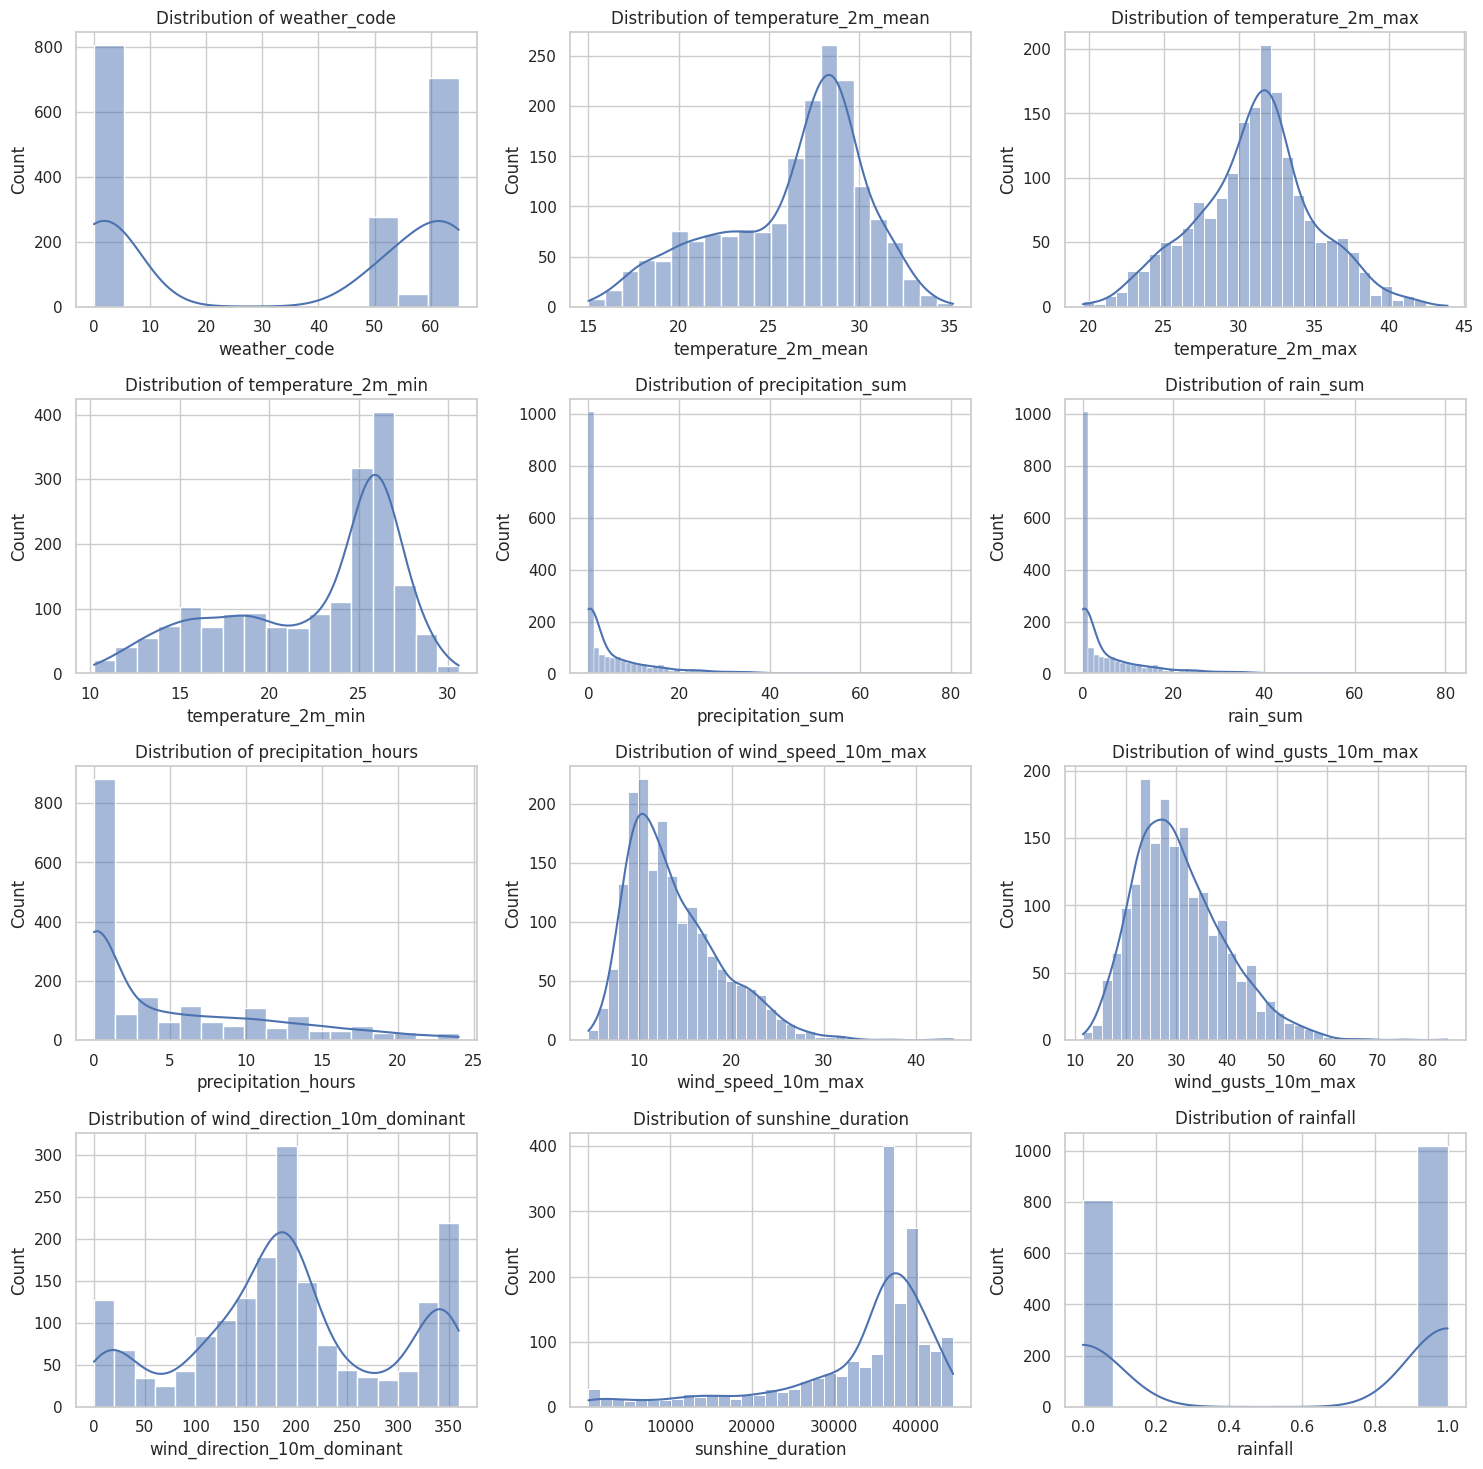

In [ ]:
plt.figure(figsize=(15, 18))
# Excluded 'city', 'sunrise', and 'sunset' as they contain non-numerical string values
columns_to_plot = ['weather_code', 'temperature_2m_mean', 'temperature_2m_max',
                   'temperature_2m_min', 'precipitation_sum', 'rain_sum',
                   'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max',
                   'wind_direction_10m_dominant', 'sunshine_duration',
                   'rainfall']

for i, column in enumerate(columns_to_plot, 1):
  # 5 rows and 3 columns can hold up to 15 subplots
  plt.subplot(5, 3, i)
  sns.histplot(data[column], kde=True)
  plt.title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

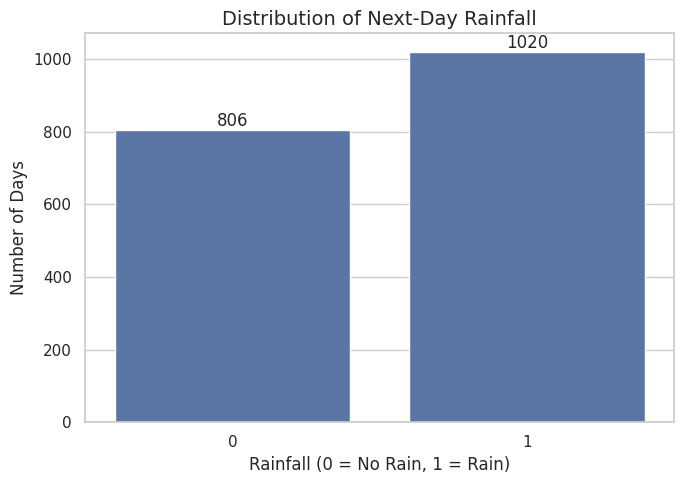


Rainfall Percentage:
rainfall
1    55.859803
0    44.140197
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(x='rainfall', data=data)

plt.title('Distribution of Next-Day Rainfall', fontsize=14)
plt.xlabel('Rainfall (0 = No Rain, 1 = Rain)')
plt.ylabel('Number of Days')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("\nRainfall Percentage:")
print(data['rainfall'].value_counts(normalize=True) * 100)

# **Feature Engineering & Data Splitting**

In [ ]:
# Use original weather data for future prediction
feature_data = raw_data.copy()

# Cyclical month features
feature_data['month'] = feature_data['time'].dt.month

feature_data['month_sin'] = np.sin(
    2 * np.pi * feature_data['month'] / 12
)

feature_data['month_cos'] = np.cos(
    2 * np.pi * feature_data['month'] / 12
)

# Cyclical wind direction
feature_data['wind_direction_sin'] = np.sin(
    np.radians(feature_data['wind_direction_10m_dominant'])
)

feature_data['wind_direction_cos'] = np.cos(
    np.radians(feature_data['wind_direction_10m_dominant'])
)

# Lag features
lag_columns = [
    'rain_sum',
    'precipitation_sum',
    'precipitation_hours',
    'temperature_2m_mean',
    'wind_speed_10m_max',
    'sunshine_duration'
]

for col in lag_columns:
    for lag in [1, 2, 3, 7]:
        feature_data[f'{col}_lag_{lag}'] = (
            feature_data[col].shift(lag)
        )

# Rolling rainfall averages
feature_data['rainfall_rolling_3'] = (
    feature_data['rain_sum'].shift(1).rolling(3).mean()
)

feature_data['rainfall_rolling_7'] = (
    feature_data['rain_sum'].shift(1).rolling(7).mean()
)

# Select features
features = [
    'weather_code',
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'sunshine_duration',
    'rain_sum',
    'precipitation_sum',
    'precipitation_hours',
    'month_sin',
    'month_cos',
    'wind_direction_sin',
    'wind_direction_cos'
]

for col in lag_columns:
    for lag in [1, 2, 3, 7]:
        features.append(f'{col}_lag_{lag}')

features += [
    'rainfall_rolling_3',
    'rainfall_rolling_7'
]

# Create feature dataset
X_all = feature_data[features].copy()

# Historical samples with known targets
X = X_all.loc[data.index].copy()
y = data.loc[X.index, 'rainfall'].copy()

# Remove rows with missing historical features
valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Preserve latest weather observation for future prediction
X_future = X_all.iloc[[-1]].copy()

if X_future.isna().any().any():
    raise ValueError(
        "Latest weather observation has missing feature values."
    )

# Chronological train-test split
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index - 1]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index - 1]
y_test = y.iloc[split_index:]

print("Feature Engineering Completed!")
print("Total Features:", len(features))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Future Prediction Date:",
      feature_data['time'].iloc[-1])


Feature Engineering Completed!
Total Features: 40
Training Samples: 1454
Testing Samples: 364
Future Prediction Date: 2026-06-30 00:00:00


# **Model Training and Comparison**

In [ ]:
# Split training data into training and validation sets
validation_split = int(len(X_train) * 0.80)

X_train_sub = X_train.iloc[:validation_split]
X_val = X_train.iloc[validation_split:]

y_train_sub = y_train.iloc[:validation_split]
y_val = y_train.iloc[validation_split:]

# Define machine learning models
models = {
    "Dummy Classifier": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        max_features="sqrt"
    )
}

# Train and evaluate each model
results = []

for name, model in models.items():

    model.fit(X_train_sub, y_train_sub)

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val, predictions
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

# Display comparison results
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
)

print("MODEL COMPARISON RESULTS")
display(comparison_df.round(4))


MODEL COMPARISON RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Random Forest,0.8247,0.8252,0.8194,0.8223,0.8920
1,Logistic Regression,0.8110,0.8201,0.7917,0.8057,0.9065
2,Decision Tree,0.7354,0.7279,0.7431,0.7354,0.7355
0,Dummy Classifier,0.4948,0.4948,1.0000,0.6621,0.5000


# **Hyperparameter Tuning**

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, None],
    "max_features": ["sqrt"],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

tscv = TimeSeriesSplit(n_splits=3, gap=1)

grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

best_rf_model = grid_search_rf.best_estimator_

print("Best Parameters:", grid_search_rf.best_params_)
print("Best CV F1 Score:", round(grid_search_rf.best_score_, 4))


Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1 Score: 0.8644


# **Cross-Validation**

In [ ]:
print("CROSS-VALIDATION RESULTS")
print("=" * 40)

# Perform cross-validation to get both accuracy and f1 metrics
from sklearn.model_selection import cross_validate

# We will use the same TimeSeriesSplit setup as in hyperparameter tuning (n_splits=3)
tscv_cv = TimeSeriesSplit(n_splits=3, gap=1)

# Evaluate the best estimator on both metrics
cv_results = cross_validate(
    best_rf_model,
    X_train,
    y_train,
    cv=tscv_cv,
    scoring=["accuracy", "f1"],
    n_jobs=-1
)

f1_scores = cv_results['test_f1']
accuracy_scores = cv_results['test_accuracy']
n_splits = len(f1_scores)

for i in range(n_splits):
    f1 = f1_scores[i]
    accuracy = accuracy_scores[i]

    print(f"\nFold {i + 1}:")
    print("F1 Score:", round(f1, 4))
    print("Accuracy:", round(accuracy * 100, 2), "%")

print("\n" + "=" * 40)
print("AVERAGE CROSS-VALIDATION RESULTS")

print("Mean F1 Score:", round(sum(f1_scores) / n_splits, 4))
print("Mean Accuracy:", round(sum(accuracy_scores) / n_splits * 100, 2), "%")

print("\nF1 Score Standard Deviation:",
      round(__import__('numpy').std(f1_scores), 4))

print("\nCross-validation completed successfully!")

CROSS-VALIDATION RESULTS

Fold 1:
F1 Score: 0.8982
Accuracy: 89.26 %

Fold 2:
F1 Score: 0.8135
Accuracy: 80.17 %

Fold 3:
F1 Score: 0.8815
Accuracy: 86.23 %

AVERAGE CROSS-VALIDATION RESULTS
Mean F1 Score: 0.8644
Mean Accuracy: 85.22 %

F1 Score Standard Deviation: 0.0366

Cross-validation completed successfully!


In [ ]:

from sklearn.base import clone

evaluation_models = {
    "Logistic Regression": clone(models["Logistic Regression"]),
    "Decision Tree": clone(models["Decision Tree"]),
    "Random Forest": clone(best_rf_model)
}

evaluation_results = []

for name, model in evaluation_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("FINAL MODEL EVALUATION")
display(
    evaluation_df.sort_values(
        by="F1 Score", ascending=False
    ).round(4)
)


FINAL MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,90.6593,0.8981,0.9417,0.9194,0.9632
0,Logistic Regression,89.8352,0.8930,0.9320,0.9121,0.9625
1,Decision Tree,84.6154,0.8606,0.8689,0.8647,0.8427


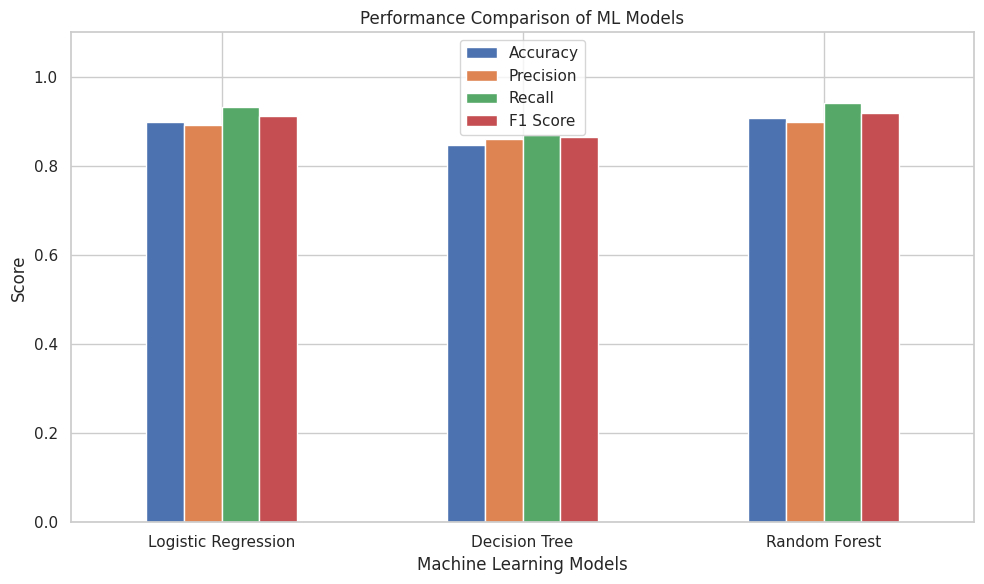

In [ ]:
# Model Performance Comparison

plot_df = evaluation_df.copy()

plot_df["Accuracy"] = plot_df["Accuracy"] / 100

plot_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# **Model Evaluation**

FINAL MODEL PERFORMANCE
Accuracy: 90.66 %
Precision: 0.8981
Recall: 0.9417
F1 Score: 0.9194

Classification Report:
              precision    recall  f1-score   support

     No Rain       0.92      0.86      0.89       158
        Rain       0.90      0.94      0.92       206

    accuracy                           0.91       364
   macro avg       0.91      0.90      0.90       364
weighted avg       0.91      0.91      0.91       364



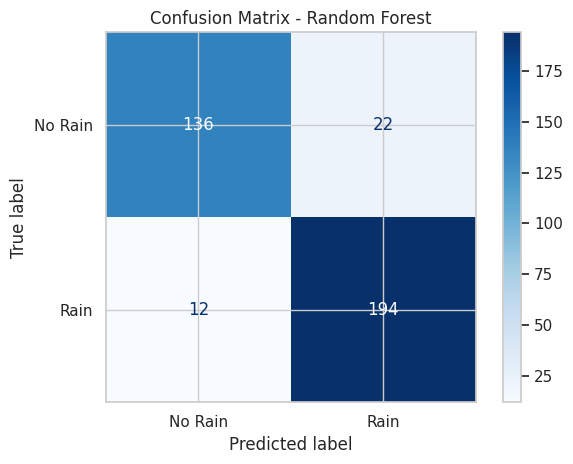

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = best_rf_model.predict(X_test)

print("FINAL MODEL PERFORMANCE")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Rain", "Rain"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Rain", "Rain"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = "Random Forest"
best_model = best_rf_model

print("SELECTED FINAL MODEL")
print("==============================")

print("Model:", best_model_name)
print("Selection Metric: F1 Score")
print("Best CV F1 Score:",
      round(grid_search_rf.best_score_, 4))

SELECTED FINAL MODEL
Model: Random Forest
Selection Metric: F1 Score
Best CV F1 Score: 0.8644


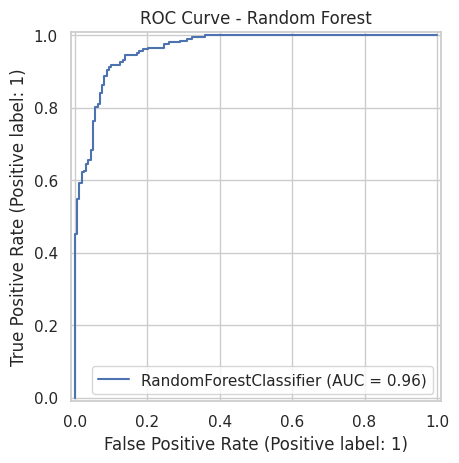

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Fix: Use the correct variable 'best_rf_model' defined in your notebook
best_model_name = "Random Forest"

RocCurveDisplay.from_estimator(
    best_rf_model,
    X_test,
    y_test
)

plt.title("ROC Curve - " + best_model_name)
plt.show()

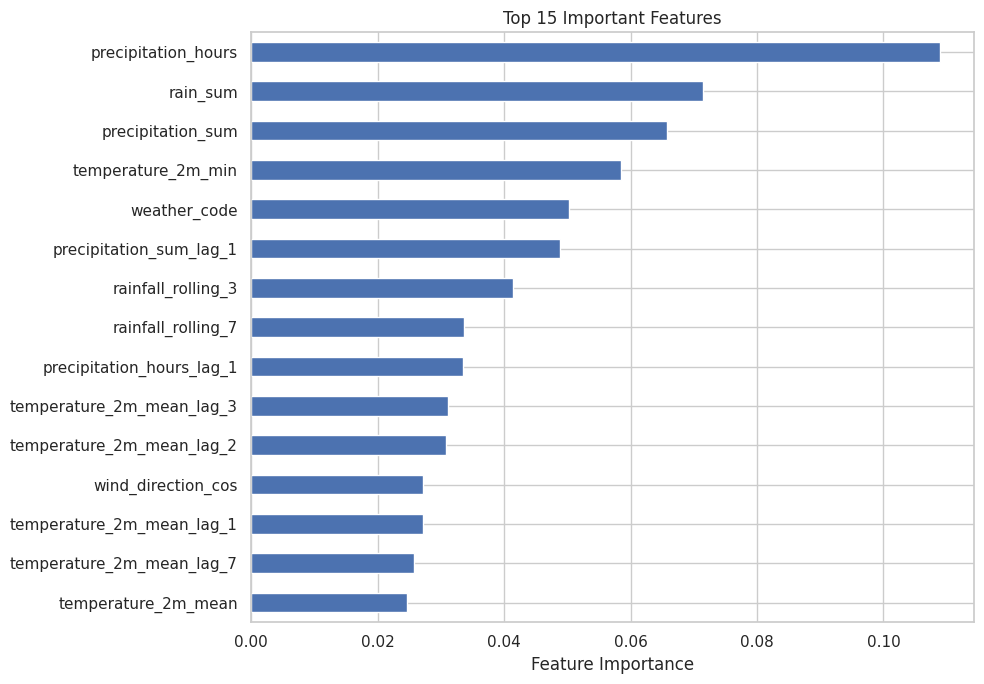

In [ ]:

if best_model_name == "Random Forest":

    # Fix: Use 'best_rf_model' instead of 'best_model'
    importance = pd.Series(
        best_model.feature_importances_,
        index=X_train.columns
    ).sort_values(ascending=False)

    plt.figure(figsize=(10, 7))

    importance.head(15).sort_values().plot(
        kind="barh"
    )

    plt.title("Top 15 Important Features")
    plt.xlabel("Feature Importance")
    plt.tight_layout()
    plt.show()

else:
    print("Feature importance plot is available here for Random Forest.")


In [ ]:

import pickle

# Fix: Use 'best_rf_model' which is defined in your kernel instead of 'best_model'
with open("best_rainfall_model.pkl", "wb") as file:
    pickle.dump(best_rf_model, file)

print("Best model saved successfully!")
print("Selected Model:", best_model_name)

Best model saved successfully!
Selected Model: Random Forest


# **Rainfall Prediction**

In [ ]:

# Final Rainfall Prediction with Probability

# Generate prediction
prediction = best_model.predict(X_future)[0]

# Calculate prediction probabilities
probabilities = best_model.predict_proba(X_future)[0]

# Identify class positions
no_rain_index = list(best_model.classes_).index(0)
rain_index = list(best_model.classes_).index(1)

# Extract probabilities
no_rain_probability = probabilities[no_rain_index] * 100
rain_probability = probabilities[rain_index] * 100

# Dates
last_observation_date = pd.to_datetime(
    raw_data["time"].iloc[-1]
)

prediction_date = last_observation_date + pd.Timedelta(days=1)

# Display final output
print("\n" + "=" * 48)
print("          RAINFALL PREDICTION")
print("=" * 48)

print("Last Observation Date:",
      last_observation_date.strftime("%d %B %Y"))

print("Prediction Date:",
      prediction_date.strftime("%d %B %Y"))

print("-" * 48)

if prediction == 1:
    print("             WILL RAIN")
else:
    print("           WILL NOT RAIN")

print("-" * 48)

print("Rain Probability:     {:.2f}%".format(
    rain_probability
))

print("No Rain Probability:  {:.2f}%".format(
    no_rain_probability
))

print("-" * 48)

print("Model Used:", best_model_name)

print("=" * 48)



          RAINFALL PREDICTION
Last Observation Date: 30 June 2026
Prediction Date: 01 July 2026
------------------------------------------------
             WILL RAIN
------------------------------------------------
Rain Probability:     99.38%
No Rain Probability:  0.62%
------------------------------------------------
Model Used: Random Forest


## Conclusion

The project **“Rainfall Prediction Using Machine Learning”** was successfully completed with the aim of predicting rainfall based on historical weather data. Different machine learning algorithms, such as Logistic Regression, Decision Tree and Random Forest, were implemented and compared to identify the most suitable model.

The performance of these models was evaluated using various evaluation metrics, including Accuracy, Precision, Recall, F1-Score and ROC-AUC. Cross-validation, hyperparameter tuning, confusion matrix and ROC curve analysis were also performed to examine the reliability and effectiveness of the models.

Among the models tested, Random Forest achieved the highest test accuracy of **90.66%**, demonstrating promising results in predicting rainfall. This project helped in understanding how machine learning can analyse weather patterns and make predictions based on historical data.

In conclusion, machine learning can be a useful tool in weather forecasting and may contribute to better planning in agriculture, water management and everyday activities. Although the model has certain limitations, further improvements using larger datasets and additional weather parameters could make rainfall prediction more reliable in the future.